In [ ]:
# 0. Подготовка данных, проверки, маскирование ID

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns
from scipy import stats
import plotly.express as px
from IPython.display import HTML

# --- Путь к данным через src.paths ---
_root = Path.cwd()
while not (_root / 'src').is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.paths import get_base_path

BASE_PATH = get_base_path()

# --- Загрузка ---
playlists_metadata = pd.read_parquet(BASE_PATH / 'playlists_metadata.parquet')
playlist_links = pd.read_parquet(BASE_PATH / 'playlist_links.parquet')
tracks_exportify = pd.read_parquet(BASE_PATH / 'tracks_exportify.parquet')
owner_ids_df = pd.read_parquet(BASE_PATH / 'owner_ids.parquet')
df_events = pd.read_parquet(BASE_PATH / 'eda_ready.parquet')
track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')


from src.paths import get_base_path
from src.mask import mask_all

BASE_PATH = get_base_path()

# --- Загрузка ---
playlists_metadata   = pd.read_parquet(BASE_PATH / 'playlists_metadata.parquet')
playlist_links       = pd.read_parquet(BASE_PATH / 'playlist_links.parquet')
tracks_exportify     = pd.read_parquet(BASE_PATH / 'tracks_exportify.parquet')
owner_ids_df         = pd.read_parquet(BASE_PATH / 'owner_ids.parquet')
df_events            = pd.read_parquet(BASE_PATH / 'eda_ready.parquet')
track_dates          = pd.read_parquet(BASE_PATH / 'track_dates.parquet')

# --- Маскирование ---
masked = mask_all(
    eda_ready=df_events,
    playlist_links=playlist_links,
    playlists_metadata=playlists_metadata,
    owner_ids=owner_ids_df,
    tracks_exportify=tracks_exportify,
)

df_events            = masked['eda_ready']
playlist_links       = masked['playlist_links']
playlists_metadata   = masked['playlists_metadata']
owner_ids_df         = masked['owner_ids']
tracks_exportify     = masked['tracks_exportify']
# ============================================================
# Порядок и цвета типов плейлистов
# ============================================================
type_order = ['personal', 'collaborative', 'contributed', 'foreign']
colors_map = {
    'personal': '#66b3ff',
    'collaborative': '#ffcc99',
    'contributed': '#99ff99',
    'foreign': '#d3d3d3',
}
# Единая палитра для всего ноутбука.
COLORS = {
    # My Music (для совместимости с 03)
    'playlist': '#66b3ff',
    'liked': '#ff9999',
    'both': '#99ff99',
    'my_music': '#99ff99',
    'other_music': '#c6dbef',
    'other_playlist': '#99e6e6',

    # Типы сессий (для совместимости)
    'continuous': '#99ff99',
    'interrupted': '#99e6e6',

    # Обсессии (для совместимости)
    'base_obs': '#66b3ff',
    'strong_obs': '#ff9999',

    # Нейтральные
    'primary': '#66b3ff',
    'secondary': '#99e6e6',
    'accent': '#ff9999',
    'success': '#99ff99',
    'muted': '#d3d3d3',

    # Насыщенные для линий
    'line_primary': '#4C9FE8',
    'line_secondary': '#26A6A6',
    'line_success': '#4CAF50',
    'line_accent': '#E86B6B',
}

# ============================================================
# Валидные прослушивания
# ============================================================
EXCLUDE_REASONS = ['trackerror', 'fwdbtn', 'backbtn', 'logout', 'remote', 'unexpected-exit']
df_events['valid_play'] = (
    (df_events['ms_played'] >= 30_000) &
    (~df_events['is_skip']) &
    (~df_events['reason_end'].isin(EXCLUDE_REASONS)) &
    (df_events['played_frac'] >= 0.5)
)


# ============================================================
# Проверка обязательных колонок
# ============================================================
required_cols = {
    'playlist_links': ['Track URI', 'Added By', 'Added At', 'playlist_name', 'name_norm', 'playlist_type', 'has_external_adders'],
    'playlists_metadata': ['account', 'playlist_name', 'name_norm', 'owner_id', 'collaborative', 'collaborators', 'number_of_followers', 'last_modified', 'num_tracks'],
    'tracks_exportify': ['spotify_track_uri', 'valence', 'energy', 'danceability', 'acousticness', 'instrumentalness', 'popularity', 'tempo', 'explicit', 'genres_normalized'],
    'df_events': ['spotify_track_uri', 'ts', 'ms_played', 'duration_ms', 'played_frac', 'is_skip'],
    'track_dates': ['spotify_track_uri', 'library_added_at', 'first_playlist_added_at'],
}

missing = []
for df_name, cols in required_cols.items():
    absent = [c for c in cols if c not in globals()[df_name].columns]
    if absent:
        missing.append(f'{df_name}: {absent}')

if missing:
    print('❌ Missing required columns:')
    for m in missing:
        print('  ', m)
else:
    print('✅ All required columns present.')


# ============================================================
# Целостность связей
# ============================================================
links_missing = playlist_links[~playlist_links['Track URI'].isin(tracks_exportify['spotify_track_uri'])]
print(f'🔗 Links with URIs missing from tracks_exportify: {len(links_missing)}')


# ============================================================
# Обзор данных
# ============================================================
print('\n📊 Data overview:')
print(f'   playlists_metadata: {len(playlists_metadata)} rows, {playlists_metadata["playlist_name"].nunique()} playlists')
print(f'   playlist_links: {len(playlist_links)} links, {playlist_links["name_norm"].nunique()} name_norm')
print(f'   tracks_exportify: {len(tracks_exportify)} unique tracks')
print(f'   owner_ids: {len(owner_ids_masked)} masked IDs')
print(f'   df_events: {len(df_events)} events, valid_play={df_events["valid_play"].sum()}')
print(f'   track_dates: {len(track_dates)} tracks with dates')


# ============================================================
# Вспомогательные функции
# ============================================================
def show_unknown_share(data, group_name):
    """
    Проверяет долю треков без валидного жанра.
    Учитывает только 'unknown'.
    """
    total = len(data)
    if total == 0:
        print(f'⚠️ {group_name}: no data')
        return 0.0
    mask = data['genres_normalized'].eq('unknown')
    share = mask.mean()
    if share > 0.5:
        print(f'⚠️ {group_name}: {share:.1%} without valid genre — genre analysis skipped.')
    elif share > 0.3:
        print(f'⚠️ {group_name}: {share:.1%} without genre — conclusions limited.')
    else:
        print(f'✅ {group_name}: {share:.1%} without valid genre.')
    return share


def normalize_name(name):
    return name.lower().strip().replace(' ', '_').replace('*', '').replace('"', '').strip('_')


def get_valid_genre_series(series):
    return series[series.eq('unknown') == False]


def top_genres_from_series(genre_series, top_n=10):
    valid = get_valid_genre_series(genre_series)
    if valid.empty:
        return pd.Series(dtype=float)
    genres = valid.str.split(',').explode().str.strip()
    genres = genres[genres != '']
    return genres.value_counts().head(top_n)


def show_table(df, max_height='400px', precision=None):
    """Таблица со скроллом, если строк >10."""
    if hasattr(df, 'style'):
        display(df)
        return
    if len(df) > 10:
        styler = df.style.set_table_attributes(
            f'style="display:block; max-height:{max_height}; overflow-y:auto;"'
        )
        if precision is not None:
            styler = styler.format(precision=precision)
        display(styler)
    else:
        display(df)


print('\n✅ Block 0 complete. IDs and names masked.')

✅ All required columns present.
🔗 Links with URIs missing from tracks_exportify: 0

📊 Data overview:
   playlists_metadata: 13417 rows, 157 playlists
   playlist_links: 33094 links, 296 name_norm
   tracks_exportify: 24953 unique tracks
   owner_ids: 3 masked IDs
   df_events: 79752 events, valid_play=45841
   track_dates: 10315 tracks with dates

✅ Block 0 complete. IDs and names masked.


🔎 Classification conflicts: 0
📊 Playlist classification:


,Type,Count,Share (%)
№,,,
1,personal,128,43.2
2,collaborative,29,9.8
3,contributed,1,0.3
4,foreign,138,46.6


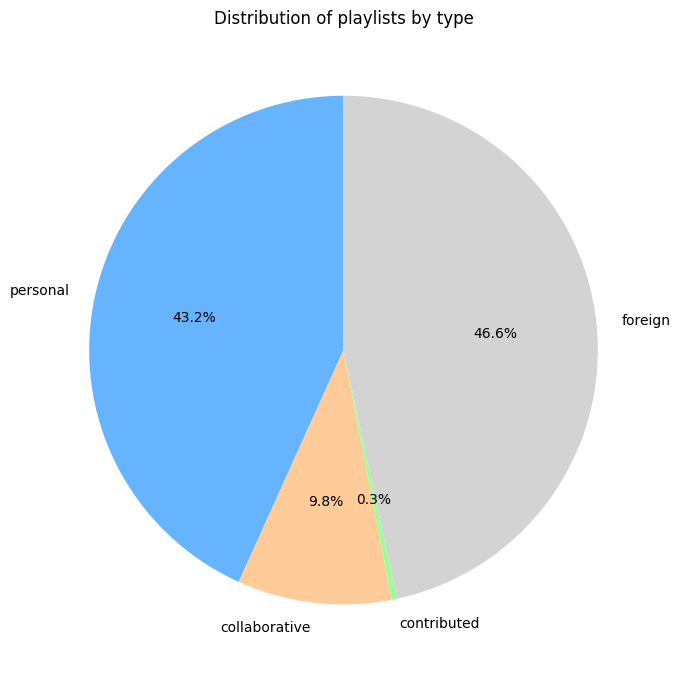


ℹ️ Analyzing valid plays (valid_play) by year.
   Categories: personal, collaborative, contributed, foreign, orphans.
   Priority for tracks in multiple types: personal > collaborative > contributed > foreign > orphan.

📊 Valid plays by year and playlist type (counts):


track_category,year,personal,collaborative,contributed,foreign,orphan
№,,,,,,
1,2020,229,6,0,89,302
2,2021,3421,69,0,622,2177
3,2022,3040,125,0,721,2390
4,2023,1820,1856,0,624,2822
5,2024,1916,645,0,528,2560
6,2025,3357,5315,0,1001,3474
7,2026,1225,2558,0,494,2455



📊 Share of categories within year (%):


track_category,year,personal,collaborative,contributed,foreign,orphan
№,,,,,,
1,2020,36.6,1.0,0.0,14.2,48.2
2,2021,54.4,1.1,0.0,9.9,34.6
3,2022,48.4,2.0,0.0,11.5,38.1
4,2023,25.6,26.1,0.0,8.8,39.6
5,2024,33.9,11.4,0.0,9.3,45.3
6,2025,25.5,40.4,0.0,7.6,26.4
7,2026,18.2,38.0,0.0,7.3,36.5


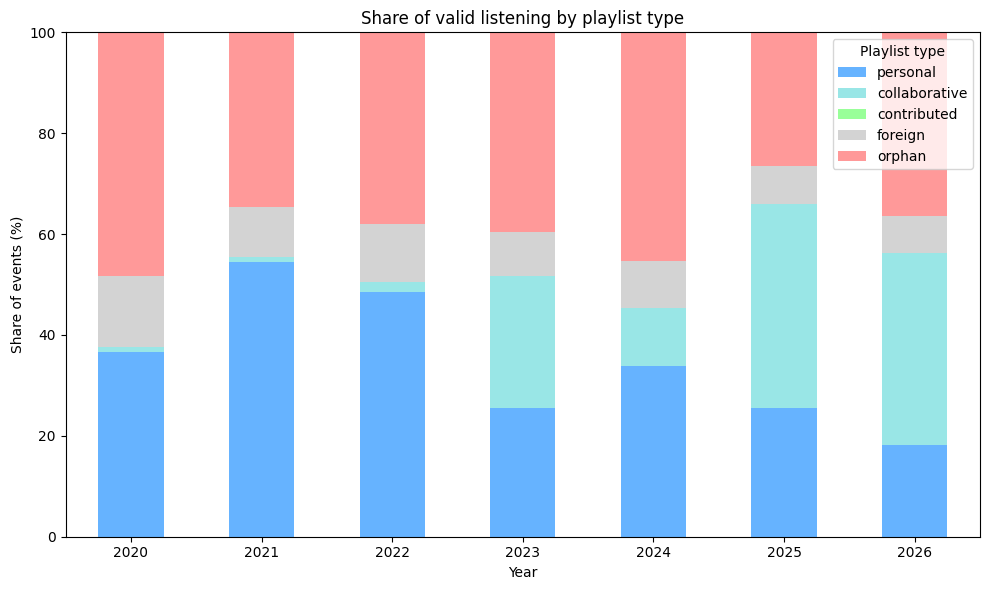

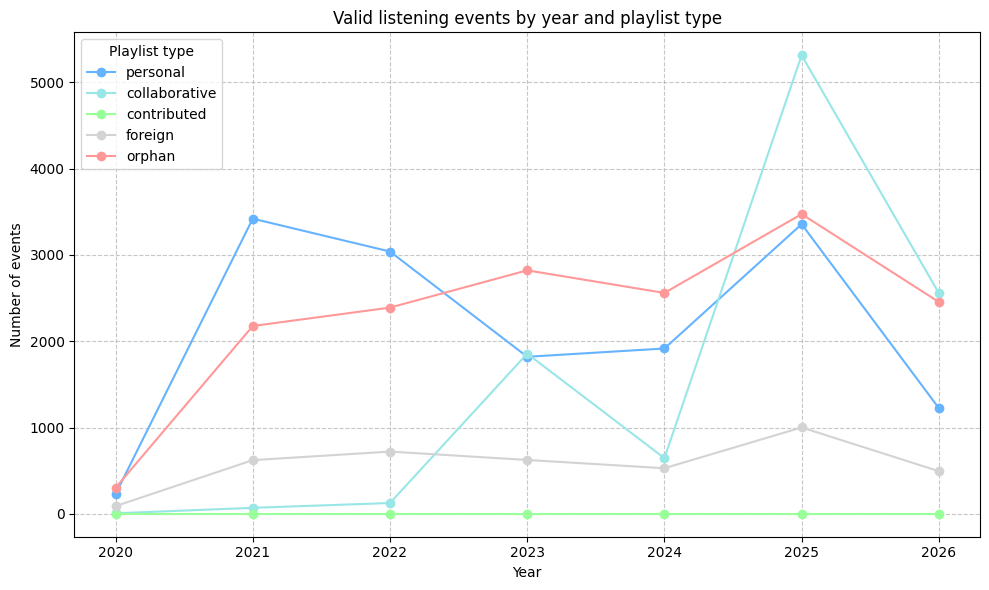

In [5]:
# 1. Типы плейлистов и временной срез прослушивания

# Две части одной логической цепочки:
#   1. Распределение плейлистов по структурным типам.
#   2. Как менялась доля прослушивания каждого типа по годам.

# ==========================================
# ЧАСТЬ 1: Распределение плейлистов по типам
# ==========================================
# Проверка согласованности классификации
multi_type = playlist_links.groupby('name_norm')['playlist_type'].nunique()
conflicts = multi_type[multi_type > 1].index.tolist()
print(f'🔎 Classification conflicts: {len(conflicts)}')
if conflicts:
    print('⚠️ Examples:', conflicts[:10])

# Уникальные плейлисты
unique_playlists = playlist_links.drop_duplicates('name_norm').copy()
type_counts = unique_playlists['playlist_type'].value_counts().reindex(type_order).fillna(0).astype(int)
type_shares = (type_counts / type_counts.sum() * 100).round(1)

summary = pd.DataFrame({
    'Type': type_counts.index,
    'Count': type_counts.values,
    'Share (%)': type_shares.values
})
summary.index = summary.index + 1
summary.index.name = '№'
print('📊 Playlist classification:')
display(summary)

# Круговая диаграмма
fig, ax = plt.subplots(figsize=(7, 7))
colors_pie = [colors_map[t] for t in type_counts.index]
wedges, texts, autotexts = ax.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_pie,
    textprops={'fontsize': 10}
)
ax.set_title('Distribution of playlists by type')
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Временной срез прослушивания по типам
# ==========================================
print('\nℹ️ Analyzing valid plays (valid_play) by year.')
print('   Categories: personal, collaborative, contributed, foreign, orphans.')
print('   Priority for tracks in multiple types: personal > collaborative > contributed > foreign > orphan.\n')

# Множества URI по типам
uri_sets = {
    'personal': set(playlist_links[playlist_links['playlist_type'] == 'personal']['Track URI']),
    'collaborative': set(playlist_links[playlist_links['playlist_type'] == 'collaborative']['Track URI']),
    'contributed': set(playlist_links[playlist_links['playlist_type'] == 'contributed']['Track URI']),
    'foreign': set(playlist_links[playlist_links['playlist_type'] == 'foreign']['Track URI']),
}


def track_category(uri):
    for ptype in ['personal', 'collaborative', 'contributed', 'foreign']:
        if uri in uri_sets[ptype]:
            return ptype
    return 'orphan'


# Валидные события с годом
valid = df_events[df_events['valid_play']].copy()
valid['year'] = pd.to_datetime(valid['ts'], errors='coerce').dt.year
valid['track_category'] = valid['spotify_track_uri'].apply(track_category)

# Таблица: год × категория
category_order = ['personal', 'collaborative', 'contributed', 'foreign', 'orphan']
cross_year = pd.crosstab(valid['year'], valid['track_category'])
cross_year = cross_year.reindex(columns=category_order, fill_value=0).sort_index()

# Доли внутри года
cross_year_pct = cross_year.div(cross_year.sum(axis=1), axis=0) * 100

# Вывод
print('📊 Valid plays by year and playlist type (counts):')
cross_year_display = cross_year.reset_index()
cross_year_display.index = range(1, len(cross_year_display) + 1)
cross_year_display.index.name = '№'
display(cross_year_display)

print('\n📊 Share of categories within year (%):')
cross_year_pct_display = cross_year_pct.round(1).reset_index()
cross_year_pct_display.index = range(1, len(cross_year_pct_display) + 1)
cross_year_pct_display.index.name = '№'
display(cross_year_pct_display)

# Палитра для категорий (личные, совместные, contributed, чужие, сироты)
category_colors = {
    'personal': COLORS['playlist'],
    'collaborative': COLORS['secondary'],
    'contributed': COLORS['success'],
    'foreign': COLORS['muted'],
    'orphan': COLORS['accent'],
}

# Stacked bar долей
ax = cross_year_pct[category_order].plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[category_colors[c] for c in category_order]
)
ax.set_title('Share of valid listening by playlist type')
ax.set_xlabel('Year')
ax.set_ylabel('Share of events (%)')
ax.legend(title='Playlist type')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# Линейный график абсолютных значений
cross_year[category_order].plot(
    kind='line', marker='o', figsize=(10, 6),
    color=[category_colors[c] for c in category_order]
)
plt.title('Valid listening events by year and playlist type')
plt.xlabel('Year')
plt.ylabel('Number of events')
plt.legend(title='Playlist type')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

📊 Playlist types summary:


,Playlists,Mean size,Median size,"Explicit, %","Unknown genres, %"
Type,,,,,
personal,128,77.3,50.0,2.7,29.1
collaborative,29,118.0,87.0,4.0,36.2
contributed,1,89.0,89.0,4.5,55.1
foreign,138,140.0,78.5,4.4,38.2


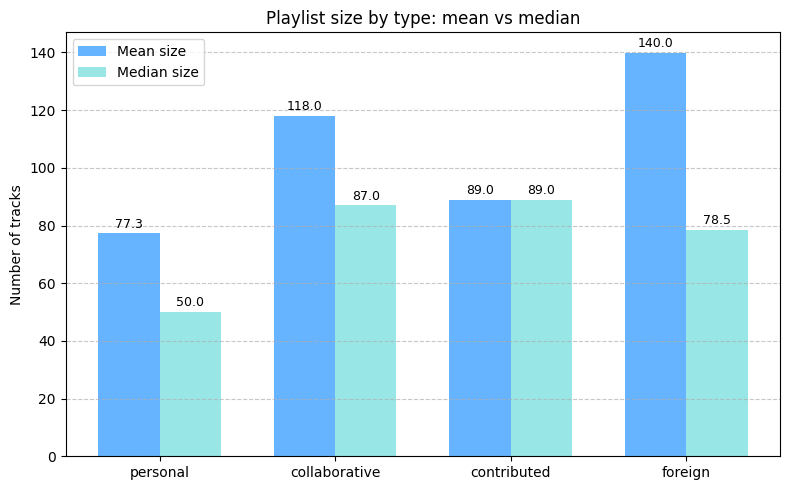

Table for the plot:


,Mean size,Median size
Type,,
personal,77.3,50.0
collaborative,118.0,87.0
contributed,89.0,89.0
foreign,140.0,78.5


Unique valid genres by type:


,Unique genres
personal,511
collaborative,294
contributed,48
foreign,601
All types,661


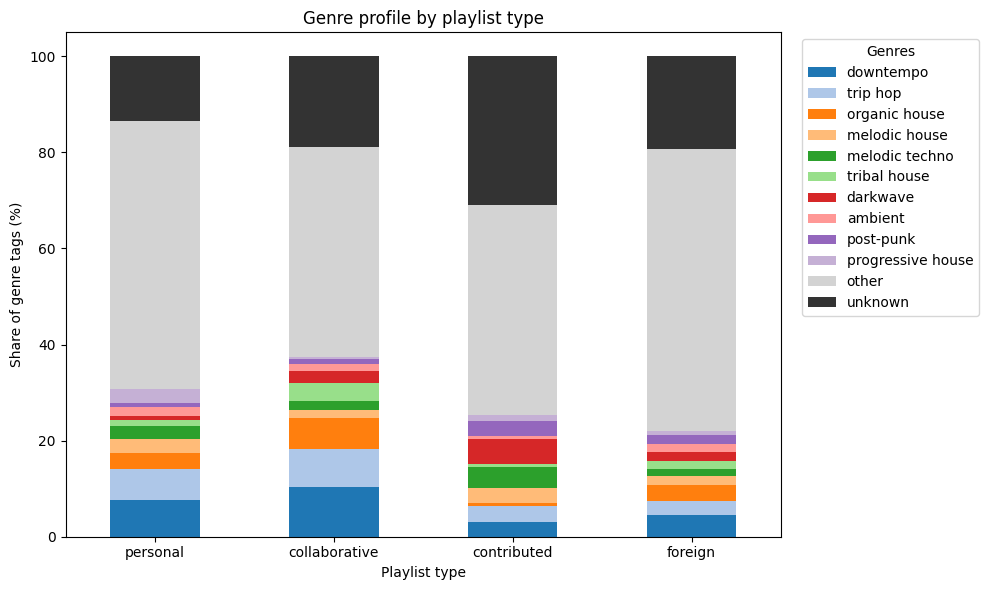

Genre shares by type (% of all genre tags):


,downtempo,trip hop,organic house,melodic house,melodic techno,tribal house,darkwave,ambient,post-punk,progressive house,other,unknown
type,,,,,,,,,,,,
personal,7.6,6.4,3.4,2.8,2.7,1.3,1.0,1.9,0.8,2.9,55.7,13.5
collaborative,10.3,7.9,6.4,1.8,1.8,3.7,2.4,1.5,1.1,0.4,43.7,18.9
contributed,3.2,3.2,0.6,3.2,4.4,0.6,5.1,0.6,3.2,1.3,43.7,31.0
foreign,4.5,3.0,3.3,1.8,1.5,1.7,1.9,1.6,1.8,0.7,58.8,19.2


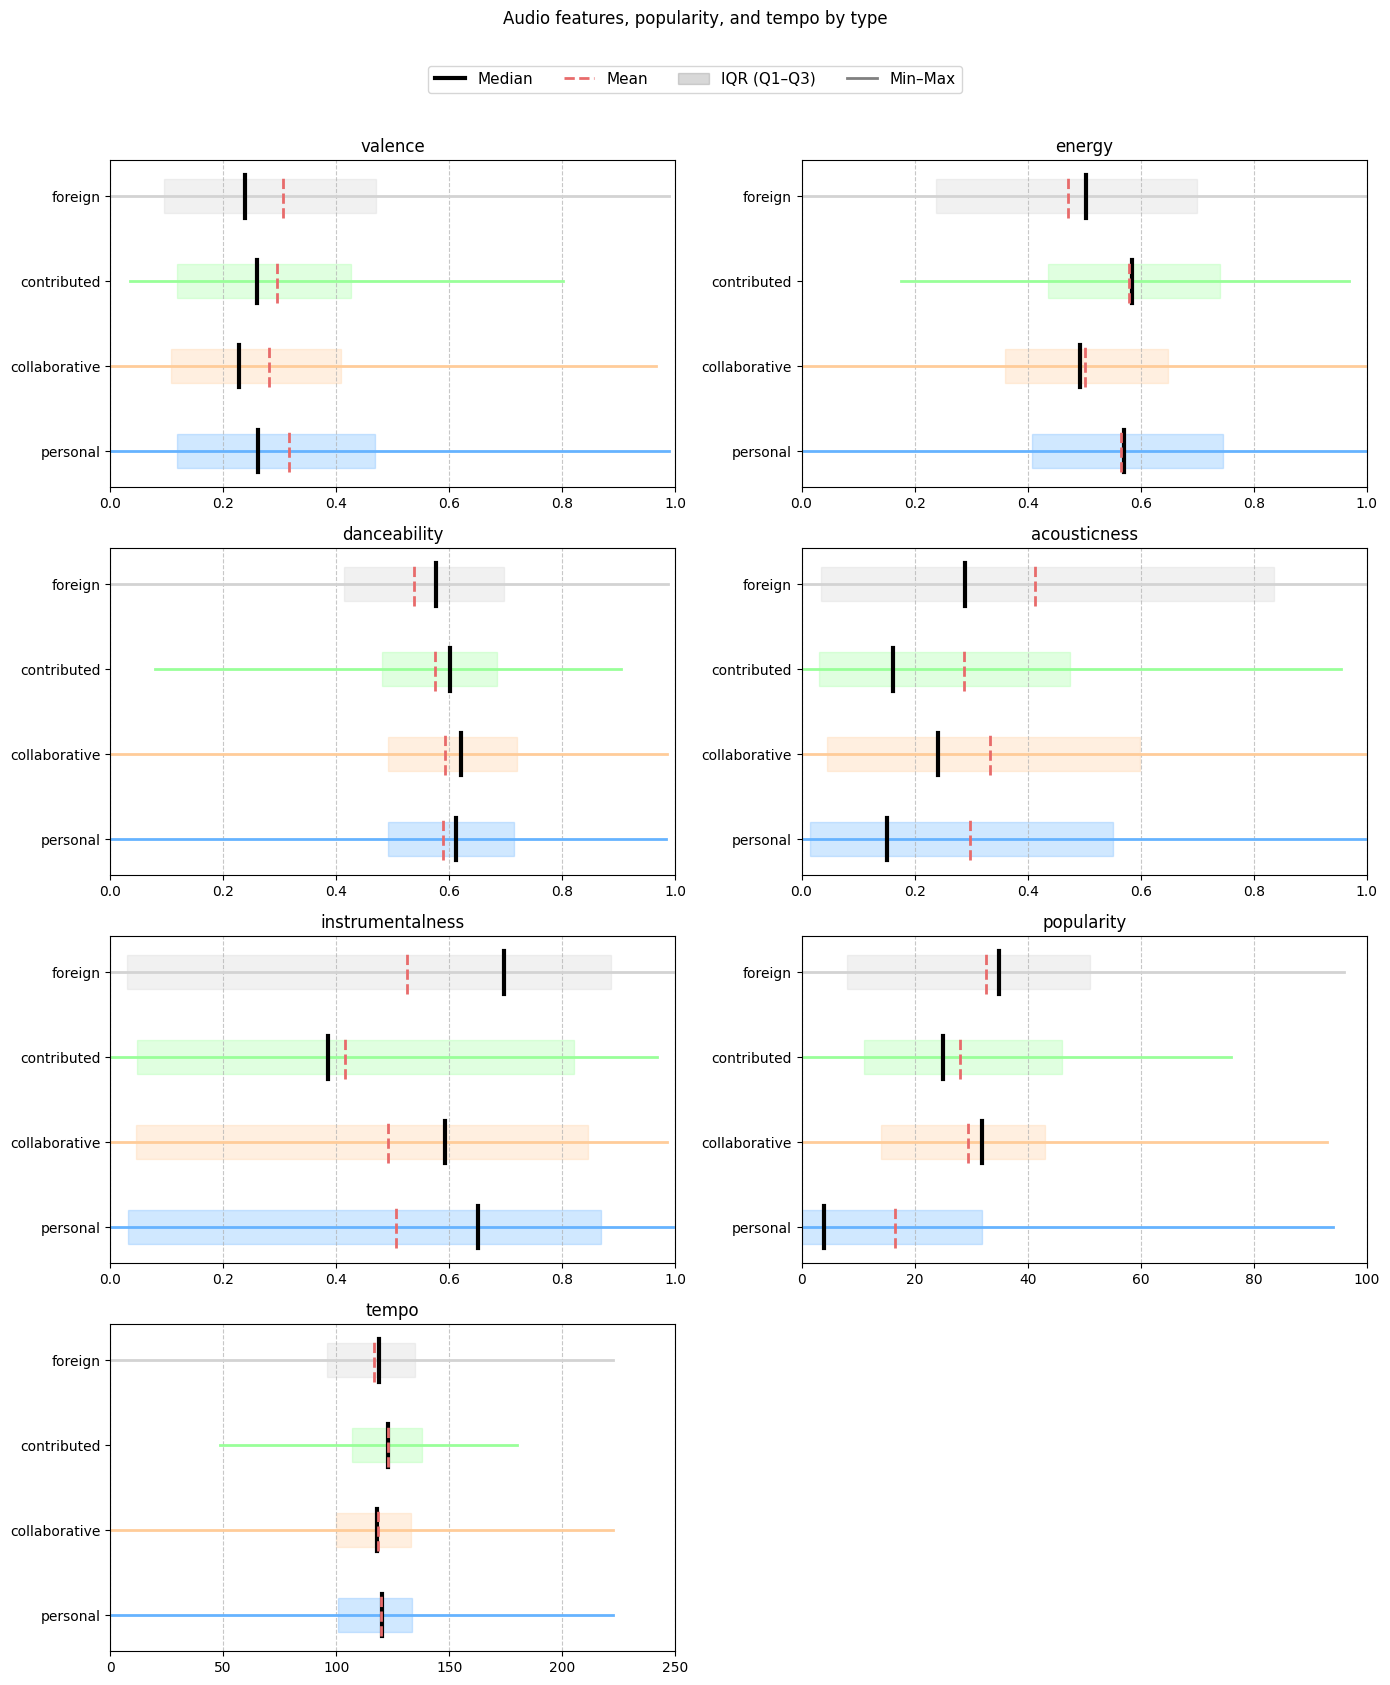

📊 valence:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,0.118,0.261,0.316,0.469,0.989
collaborative,0.000,0.107,0.228,0.280,0.408,0.965
contributed,0.036,0.119,0.259,0.294,0.426,0.801
foreign,0.000,0.095,0.239,0.305,0.470,0.989


📊 energy:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,0.407,0.571,0.565,0.745,1.000
collaborative,0.003,0.360,0.493,0.502,0.648,0.997
contributed,0.176,0.436,0.584,0.580,0.741,0.969
foreign,0.000,0.238,0.504,0.471,0.700,0.999


📊 danceability:


...

,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.0,0.032,0.650,0.505,0.868,0.995
collaborative,0.0,0.046,0.592,0.491,0.845,0.986
contributed,0.0,0.048,0.386,0.416,0.820,0.968
foreign,0.0,0.029,0.697,0.525,0.886,0.996


📊 popularity:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.0,0.0,4.0,16.528,32.0,94.0
collaborative,0.0,14.0,32.0,29.519,43.0,93.0
contributed,0.0,11.0,25.0,27.978,46.0,76.0
foreign,0.0,8.0,35.0,32.623,51.0,96.0


📊 tempo:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,101.003,120.035,119.900,133.547,222.605
collaborative,0.000,99.900,117.972,118.395,133.142,222.605
contributed,48.637,107.019,123.018,123.005,138.039,180.138
foreign,0.000,96.001,118.945,116.745,134.976,222.605


In [6]:
# 2. Музыкальное содержание по типам плейлистов

# Три части:
#   1. Общая сводка: размеры, explicit, unknown.
#   2. Жанровый профиль.
#   3. Аудио-характеристики.

# ==========================================
# ЧАСТЬ 1: Общая сводка по типам
# ==========================================
# Сохраняем уникальные треки каждого типа в словаре для следующих ячеек.
type_tracks = {}
summary_rows = []
size_data = {}

features_audio = ['valence', 'energy', 'danceability', 'acousticness',
                  'instrumentalness', 'popularity', 'tempo', 'explicit',
                  'genres_normalized']

for ptype in type_order:
    links = playlist_links[playlist_links['playlist_type'] == ptype]
    pairs = links[['name_norm', 'Track URI']].drop_duplicates()
    merged = pairs.merge(
        tracks_exportify[['spotify_track_uri'] + features_audio],
        left_on='Track URI', right_on='spotify_track_uri', how='left'
    )
    type_tracks[ptype] = merged

    sizes = pairs.groupby('name_norm')['Track URI'].count()
    size_data[ptype] = sizes

    explicit_share = merged['explicit'].mean() * 100
    unknown_mask = merged['genres_normalized'].eq('unknown')
    unknown_share = unknown_mask.mean() * 100

    summary_rows.append({
        'Type': ptype,
        'Playlists': int(pairs['name_norm'].nunique()),
        'Mean size': round(sizes.mean(), 1),
        'Median size': round(sizes.median(), 1),
        'Explicit, %': round(explicit_share, 1),
        'Unknown genres, %': round(unknown_share, 1)
    })

summary_df = pd.DataFrame(summary_rows).set_index('Type')
print('📊 Playlist types summary:')
display(summary_df)

# Bar plot: средний и медианный размер по типам
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(type_order))
width = 0.35
mean_sizes = [size_data[t].mean() for t in type_order]
median_sizes = [size_data[t].median() for t in type_order]

bars1 = ax.bar(x - width/2, mean_sizes, width, label='Mean size', color=COLORS['primary'])
bars2 = ax.bar(x + width/2, median_sizes, width, label='Median size', color=COLORS['secondary'])

ax.set_xticks(x)
ax.set_xticklabels(type_order)
ax.set_ylabel('Number of tracks')
ax.set_title('Playlist size by type: mean vs median')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar, val in zip(bars1, mean_sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{val:.1f}', ha='center', fontsize=9)
for bar, val in zip(bars2, median_sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{val:.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

size_summary = pd.DataFrame({
    'Type': type_order,
    'Mean size': mean_sizes,
    'Median size': median_sizes
}).set_index('Type')
print('Table for the plot:')
display(size_summary.round(1))


# ==========================================
# ЧАСТЬ 2: Жанровый профиль
# ==========================================
# Топ-10 жанров по всем типам, единая палитра для жанров.
playlist_type_order = ['personal', 'collaborative', 'contributed', 'foreign']

all_genres = []
for ptype in playlist_type_order:
    valid = get_valid_genre_series(type_tracks[ptype]['genres_normalized'])
    all_genres.extend(valid.str.split(',').explode().str.strip().tolist())
all_genres_series = pd.Series(all_genres)
all_genres_series = all_genres_series[all_genres_series != '']
top10_genres = all_genres_series.value_counts().head(10).index.tolist()

# Уникальные жанры по типам
total_unique_genres = all_genres_series.nunique()
unique_genres_by_type = {}
for ptype in playlist_type_order:
    valid = get_valid_genre_series(type_tracks[ptype]['genres_normalized'])
    genres_split = valid.str.split(',').explode().str.strip()
    genres_split = genres_split[genres_split != '']
    unique_genres_by_type[ptype] = genres_split.nunique()

unique_genres_by_type_series = pd.Series(unique_genres_by_type)
unique_genres_by_type_series['All types'] = total_unique_genres
print('Unique valid genres by type:')
display(unique_genres_by_type_series.to_frame('Unique genres'))

# Доли топ-10 + other + unknown
share_rows = []
for ptype in playlist_type_order:
    series = type_tracks[ptype]['genres_normalized']
    total_tags = 0
    unknown_count = 0
    other_count = 0
    top_counts = {g: 0 for g in top10_genres}

    for genres in series.dropna():
        tags = [t.strip() for t in genres.split(',')]
        for tag in tags:
            if tag == '' or tag == 'unknown':
                unknown_count += 1
                total_tags += 1
            elif tag in top_counts:
                top_counts[tag] += 1
                total_tags += 1
            else:
                other_count += 1
                total_tags += 1

    if total_tags == 0:
        shares = [0] * len(top10_genres) + [0, 0]
    else:
        shares = [top_counts[g] / total_tags * 100 for g in top10_genres]
        shares += [other_count / total_tags * 100, unknown_count / total_tags * 100]
    share_rows.append([ptype] + shares)

share_df = pd.DataFrame(share_rows, columns=['type'] + top10_genres + ['other', 'unknown'])
share_df = share_df.set_index('type')

# Цвета для жанров
tab20 = plt.cm.tab20.colors
genre_colors = {g: tab20[i % len(tab20)] for i, g in enumerate(top10_genres)}
genre_colors['other'] = COLORS['muted']
genre_colors['unknown'] = '#333333'

# Stacked bar
ax = share_df.plot(kind='bar', stacked=True, figsize=(10, 6),
                   color=[genre_colors[g] for g in share_df.columns])
ax.set_title('Genre profile by playlist type')
ax.set_xlabel('Playlist type')
ax.set_ylabel('Share of genre tags (%)')
ax.legend(title='Genres', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print('Genre shares by type (% of all genre tags):')
display(share_df.round(1))


# ==========================================
# ЧАСТЬ 3: Аудио-характеристики
# ==========================================
features_plot = ['valence', 'energy', 'danceability', 'acousticness',
                 'instrumentalness', 'popularity', 'tempo']
xlims = {
    'valence': (0, 1), 'energy': (0, 1), 'danceability': (0, 1),
    'acousticness': (0, 1), 'instrumentalness': (0, 1),
    'popularity': (0, 100), 'tempo': (0, 250)
}

# Range plot 4×2
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, feat in enumerate(features_plot):
    ax = axes[idx]
    xmin, xmax = xlims[feat]
    for j, ptype in enumerate(type_order):
        data = type_tracks[ptype][feat].dropna()
        if len(data) == 0:
            continue
        median = data.median()
        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        min_val = data.min()
        max_val = data.max()
        y_pos = j

        ax.plot([min_val, max_val], [y_pos, y_pos], color=colors_map[ptype], lw=2)
        ax.add_patch(plt.Rectangle((q1, y_pos - 0.2), q3 - q1, 0.4,
                                   color=colors_map[ptype], alpha=0.3))
        ax.plot([median, median], [y_pos - 0.25, y_pos + 0.25], color='black', lw=3)
        ax.plot([data.mean(), data.mean()], [y_pos - 0.25, y_pos + 0.25],
                color=COLORS['line_accent'], lw=2, linestyle='--')

    ax.set_title(feat)
    ax.set_yticks(range(4))
    ax.set_yticklabels(type_order)
    ax.set_xlim(xmin, xmax)
    ax.grid(axis='x', linestyle='--', alpha=0.7)

axes[-1].axis('off')

# Легенда
median_handle = mlines.Line2D([], [], color='black', lw=3, label='Median')
mean_handle = mlines.Line2D([], [], color=COLORS['line_accent'], lw=2,
                            linestyle='--', label='Mean')
iqr_handle = mpatches.Patch(color='gray', alpha=0.3, label='IQR (Q1–Q3)')
minmax_handle = mlines.Line2D([], [], color='gray', lw=2, label='Min–Max')
fig.legend(handles=[median_handle, mean_handle, iqr_handle, minmax_handle],
           loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=11)
plt.suptitle('Audio features, popularity, and tempo by type', y=1.05)
plt.tight_layout()
plt.show()

# Таблицы по каждой характеристике
for feat in features_plot:
    table_rows = []
    for ptype in type_order:
        data = type_tracks[ptype][feat].dropna()
        table_rows.append({
            'Type': ptype,
            'Min': data.min(),
            'Q1': data.quantile(0.25),
            'Median': data.median(),
            'Mean': data.mean(),
            'Q3': data.quantile(0.75),
            'Max': data.max()
        })
    feat_table = pd.DataFrame(table_rows).set_index('Type')
    if feat in ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']:
        fmt = '{:.3f}'
    else:
        fmt = '{:.1f}'
    print(f'📊 {feat}:')
    display(feat_table.round(3))

📊 Intersection matrix, unique tracks (absolute):


Type,personal,collaborative,contributed,foreign
Type,,,,
personal,7962.0,636.0,89.0,1582.0
collaborative,636.0,2389.0,5.0,1315.0
contributed,89.0,5.0,89.0,21.0
foreign,1582.0,1315.0,21.0,17694.0



📊 Share of row type (%):


Type,personal,collaborative,contributed,foreign
Type,,,,
personal,100.0,8.0,1.1,19.9
collaborative,26.6,100.0,0.2,55.0
contributed,100.0,5.6,100.0,23.6
foreign,8.9,7.4,0.1,100.0


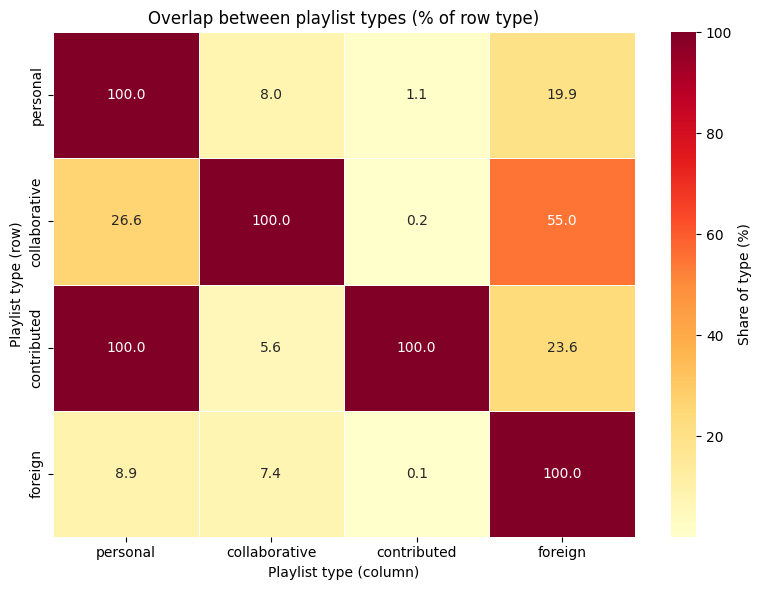

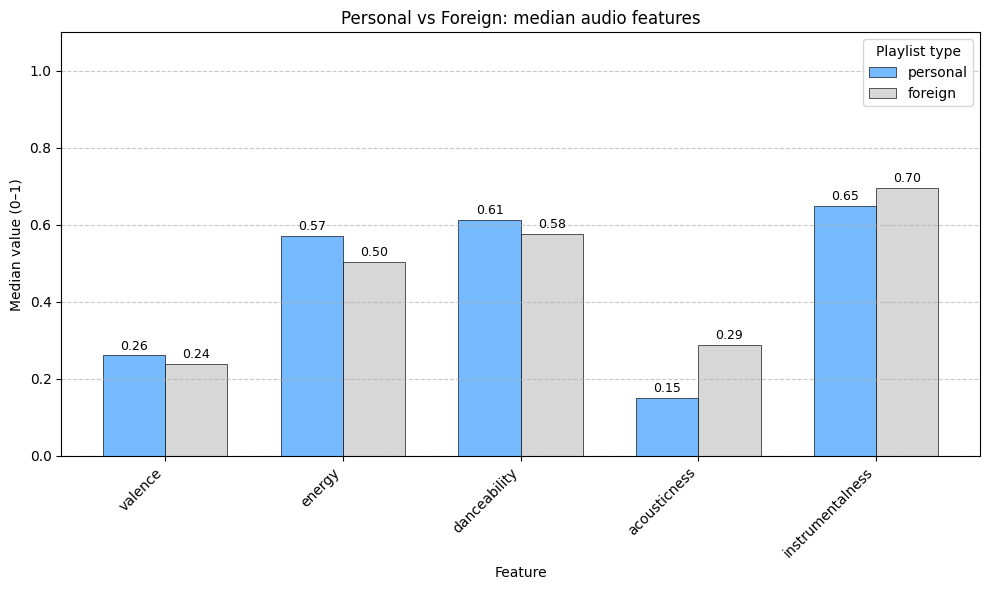

📊 personal vs foreign (0–1 features):


,Feature,personal median,foreign median,Mean diff,Threshold,p-value,Verdict,Note
№,,,,,,,,
1,valence,0.261,0.239,0.010,0.02,3.018e-09,⚠️,"significant, but small"
2,energy,0.571,0.504,0.094,0.02,1.525e-135,✅,significant and meaningful
3,danceability,0.612,0.576,0.051,0.02,4.101e-69,✅,significant and meaningful
4,acousticness,0.151,0.289,-0.114,0.02,2.835e-135,✅,significant and meaningful
5,instrumentalness,0.650,0.697,-0.020,0.02,1.715e-11,⚠️,"significant, but small"


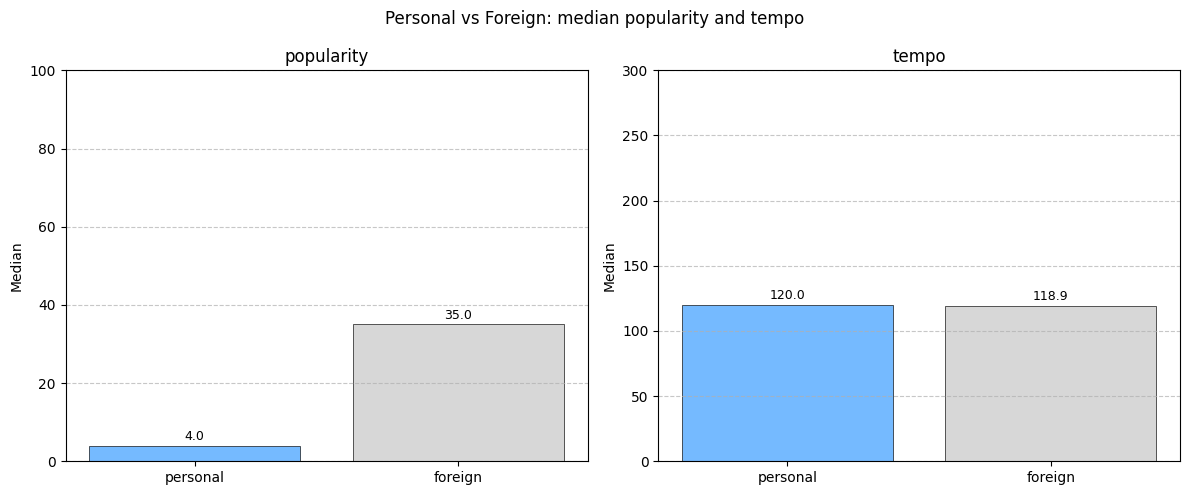

📊 personal vs foreign (popularity, tempo):


,Feature,personal median,foreign median,Mean diff,Threshold,p-value,Verdict,Note
№,,,,,,,,
1,popularity,4.0,35.0,-16.1,5.0,0.000e+00,✅,significant and meaningful
2,tempo,120.0,118.9,3.2,2.0,5.076e-19,✅,significant and meaningful



🔍 Auto conclusion:
• personal: energy higher (0.57 vs 0.50), danceability higher (0.61 vs 0.58), tempo higher (120.03 vs 118.94).
• foreign: acousticness higher (0.29 vs 0.15), popularity higher (35.00 vs 4.00).

📊 Auto portraits by medians:


,Feature,🥇 Leader,🥈 Outsider,Leader median,Outsider median
№,,,,,
1,valence,personal,collaborative,0.261,0.228
2,energy,contributed,collaborative,0.584,0.493
3,danceability,collaborative,foreign,0.621,0.576
4,acousticness,foreign,personal,0.289,0.151
5,instrumentalness,foreign,contributed,0.697,0.386
6,popularity,foreign,personal,35.000,4.000
7,tempo,contributed,collaborative,123.018,117.972



📊 Overall significance (Kruskal-Wallis):


,Feature,p-value,Result
№,,,
1,valence,2.839e-11,✅ significant
2,energy,1.373e-140,✅ significant
3,danceability,3.162e-85,✅ significant
4,acousticness,2.830e-137,✅ significant
5,instrumentalness,9.469e-18,✅ significant
6,popularity,0.000e+00,✅ significant
7,tempo,2.330e-18,✅ significant



📊 Pairwise significant differences (Mann-Whitney U):


,Feature,Pair,Diff,p-value,Signif,Conclusion
№,,,,,,
1,valence,personal vs collaborative,0.035,1.667e-10,***,personal higher than collaborative
2,valence,personal vs foreign,0.010,3.018e-09,⚠️,"significant, but small"
3,valence,collaborative vs foreign,-0.025,1.707e-02,*,foreign higher than collaborative
4,energy,personal vs collaborative,0.063,1.087e-48,***,personal higher than collaborative
5,energy,personal vs foreign,0.094,1.525e-135,***,personal higher than foreign
6,energy,collaborative vs contributed,-0.078,5.741e-04,***,contributed higher than collaborative
7,energy,collaborative vs foreign,0.032,8.891e-04,***,collaborative higher than foreign
8,energy,contributed vs foreign,0.110,7.076e-04,***,contributed higher than foreign
9,danceability,personal vs foreign,0.051,4.101e-69,***,personal higher than foreign



Legend: *** p<0.001, ** p<0.01, * p<0.05
⚠️ significant, but below practical threshold


In [7]:
# 3. Сравнение типов: пересечения и контрасты

# Три части:
#   1. Пересечения уникальных треков между типами.
#   2. Личные vs чужие: аудио-профиль и значимость.
#   3. Топы и статистика по всем типам.

# ==========================================
# ЧАСТЬ 1: Пересечения треков между типами
# ==========================================
uris_by_type = {
    ptype: set(type_tracks[ptype]['spotify_track_uri'].dropna())
    for ptype in type_order
}

# Матрица абсолютных пересечений
intersection_matrix = pd.DataFrame(index=type_order, columns=type_order, dtype=int)
for i, t1 in enumerate(type_order):
    for j, t2 in enumerate(type_order):
        if i == j:
            intersection_matrix.loc[t1, t2] = len(uris_by_type[t1])
        else:
            intersection_matrix.loc[t1, t2] = len(uris_by_type[t1] & uris_by_type[t2])

intersection_matrix.index.name = 'Type'
intersection_matrix.columns.name = 'Type'

print('📊 Intersection matrix, unique tracks (absolute):')
display(intersection_matrix)

# Доли от строки
share_matrix = intersection_matrix.copy().astype(float)
for t in type_order:
    share_matrix.loc[t, :] = share_matrix.loc[t, :] / len(uris_by_type[t]) * 100

print('\n📊 Share of row type (%):')
display(share_matrix.round(1))

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    share_matrix.astype(float),
    annot=True, fmt='.1f', cmap='YlOrRd',
    cbar_kws={'label': 'Share of type (%)'},
    linewidths=0.5
)
plt.title('Overlap between playlist types (% of row type)')
plt.xlabel('Playlist type (column)')
plt.ylabel('Playlist type (row)')
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Personal vs Foreign
# ==========================================
t1 = 'personal'
t2 = 'foreign'

PRACTICAL_THRESHOLDS = {
    'valence': 0.02, 'energy': 0.02, 'danceability': 0.02,
    'acousticness': 0.02, 'instrumentalness': 0.02,
    'popularity': 5.0, 'tempo': 2.0
}
ALPHA = 0.05

# Часть 2.1: 0–1 характеристики — медианы
features_01 = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
med_t1 = [type_tracks[t1][feat].dropna().median() for feat in features_01]
med_t2 = [type_tracks[t2][feat].dropna().median() for feat in features_01]

x = np.arange(len(features_01))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, med_t1, width, label=t1,
               color=colors_map[t1], edgecolor='black', linewidth=0.5, alpha=0.9)
bars2 = ax.bar(x + width/2, med_t2, width, label=t2,
               color=colors_map[t2], edgecolor='black', linewidth=0.5, alpha=0.9)

ax.set_xlabel('Feature')
ax.set_ylabel('Median value (0–1)')
ax.set_title('Personal vs Foreign: median audio features')
ax.set_xticks(x)
ax.set_xticklabels(features_01, rotation=45, ha='right')
ax.legend(title='Playlist type')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 1.1)
ax.bar_label(bars1, fmt='%.2f', fontsize=9, padding=2)
ax.bar_label(bars2, fmt='%.2f', fontsize=9, padding=2)
plt.tight_layout()
plt.show()

# Таблица по 0–1
rows_01 = []
for feat in features_01:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    med1 = a.median()
    med2 = b.median()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    stat_sig = p < ALPHA
    pract_sig = abs(mean_diff) >= thresh
    if stat_sig and pract_sig:
        verdict, note = '✅', 'significant and meaningful'
    elif stat_sig and not pract_sig:
        verdict, note = '⚠️', 'significant, but small'
    else:
        verdict, note = '—', 'not significant'
    rows_01.append({
        'Feature': feat,
        f'{t1} median': f'{med1:.3f}',
        f'{t2} median': f'{med2:.3f}',
        'Mean diff': f'{mean_diff:.3f}',
        'Threshold': f'{thresh:.2f}',
        'p-value': f'{p:.3e}',
        'Verdict': verdict,
        'Note': note
    })
df_01 = pd.DataFrame(rows_01)
df_01.index = df_01.index + 1
df_01.index.name = '№'
print(f'📊 {t1} vs {t2} (0–1 features):')
display(df_01)

# Часть 2.2: popularity и tempo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feat, ylim, fmt in [
    (axes[0], 'popularity', 100, '%.1f'),
    (axes[1], 'tempo', 300, '%.1f')
]:
    med_t1 = type_tracks[t1][feat].dropna().median()
    med_t2 = type_tracks[t2][feat].dropna().median()
    bars = ax.bar([t1, t2], [med_t1, med_t2],
                  color=[colors_map[t1], colors_map[t2]],
                  edgecolor='black', linewidth=0.5, alpha=0.9)
    ax.set_title(feat)
    ax.set_ylabel('Median')
    ax.set_ylim(0, ylim)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.bar_label(bars, fmt=fmt, fontsize=9, padding=2)

plt.suptitle('Personal vs Foreign: median popularity and tempo')
plt.tight_layout()
plt.show()

# Таблица по popularity и tempo
rows_other = []
for feat in ['popularity', 'tempo']:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    stat_sig = p < ALPHA
    pract_sig = abs(mean_diff) >= thresh
    if stat_sig and pract_sig:
        verdict, note = '✅', 'significant and meaningful'
    elif stat_sig and not pract_sig:
        verdict, note = '⚠️', 'significant, but small'
    else:
        verdict, note = '—', 'not significant'
    rows_other.append({
        'Feature': feat,
        f'{t1} median': f'{a.median():.1f}',
        f'{t2} median': f'{b.median():.1f}',
        'Mean diff': f'{mean_diff:.1f}',
        'Threshold': f'{thresh:.1f}',
        'p-value': f'{p:.3e}',
        'Verdict': verdict,
        'Note': note
    })
df_other = pd.DataFrame(rows_other)
df_other.index = df_other.index + 1
df_other.index.name = '№'
print(f'📊 {t1} vs {t2} (popularity, tempo):')
display(df_other)

# Автоматический портрет
personal_traits = []
foreign_traits = []

for feat in features_01 + ['popularity', 'tempo']:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    p = stats.mannwhitneyu(a, b, alternative='two-sided')[1]
    if p < ALPHA and abs(mean_diff) >= thresh:
        if mean_diff > 0:
            personal_traits.append(f'{feat} higher ({a.median():.2f} vs {b.median():.2f})')
        else:
            foreign_traits.append(f'{feat} higher ({b.median():.2f} vs {a.median():.2f})')

print('\n🔍 Auto conclusion:')
if personal_traits:
    print(f'• {t1}: ' + ', '.join(personal_traits) + '.')
if foreign_traits:
    print(f'• {t2}: ' + ', '.join(foreign_traits) + '.')
if not personal_traits and not foreign_traits:
    print('No meaningful differences detected.')


# ==========================================
# ЧАСТЬ 3: Топы и статистика по типам
# ==========================================
features_all = ['valence', 'energy', 'danceability', 'acousticness',
                'instrumentalness', 'popularity', 'tempo']
types_list = type_order

# Автоматические портреты типов
portrait_rows = []
for feat in features_all:
    medians = {ptype: type_tracks[ptype][feat].dropna().median() for ptype in types_list}
    leader = max(medians, key=medians.get)
    outsider = min(medians, key=medians.get)
    portrait_rows.append({
        'Feature': feat,
        '🥇 Leader': leader,
        '🥈 Outsider': outsider,
        'Leader median': medians[leader],
        'Outsider median': medians[outsider]
    })

portrait_df = pd.DataFrame(portrait_rows)
portrait_df.index = range(1, len(portrait_df) + 1)
portrait_df.index.name = '№'
print('\n📊 Auto portraits by medians:')
display(portrait_df)

# Kruskal-Wallis
kw_results = {}
for feat in features_all:
    groups = [type_tracks[ptype][feat].dropna() for ptype in types_list]
    valid_groups = [(ptype, g) for ptype, g in zip(types_list, groups) if len(g) >= 30]
    if len(valid_groups) < 2:
        kw_results[feat] = {'p': np.nan, 'valid_types': []}
        continue
    valid_types = [ptype for ptype, _ in valid_groups]
    valid_data = [g for _, g in valid_groups]
    h_stat, p_kw = stats.kruskal(*valid_data)
    kw_results[feat] = {'p': p_kw, 'valid_types': valid_types}

kw_rows = []
for feat in features_all:
    p = kw_results[feat]['p']
    if np.isnan(p):
        verdict = '⚠️ insufficient data'
    elif p < ALPHA:
        verdict = '✅ significant'
    else:
        verdict = '— not significant'
    kw_rows.append({
        'Feature': feat,
        'p-value': f'{p:.3e}' if not np.isnan(p) else '—',
        'Result': verdict
    })
kw_df = pd.DataFrame(kw_rows)
kw_df.index = range(1, len(kw_df) + 1)
kw_df.index.name = '№'
print('\n📊 Overall significance (Kruskal-Wallis):')
display(kw_df)

# Попарные значимые различия
from itertools import combinations

pair_rows = []
for feat in features_all:
    if kw_results[feat]['p'] >= ALPHA or not kw_results[feat]['valid_types']:
        continue
    valid_types = kw_results[feat]['valid_types']
    for t1_, t2_ in combinations(valid_types, 2):
        a = type_tracks[t1_][feat].dropna()
        b = type_tracks[t2_][feat].dropna()
        if len(a) < 30 or len(b) < 30:
            continue
        u, p_pair = stats.mannwhitneyu(a, b, alternative='two-sided')
        mean_diff = a.mean() - b.mean()
        thresh = PRACTICAL_THRESHOLDS[feat]
        if p_pair < ALPHA and abs(mean_diff) >= thresh:
            stars = '***' if p_pair < 0.001 else '**' if p_pair < 0.01 else '*'
            higher, lower = (t1_, t2_) if mean_diff > 0 else (t2_, t1_)
            pair_rows.append({
                'Feature': feat,
                'Pair': f'{t1_} vs {t2_}',
                'Diff': f'{mean_diff:.3f}',
                'p-value': f'{p_pair:.3e}',
                'Signif': f'{stars}',
                'Conclusion': f'{higher} higher than {lower}'
            })
        elif p_pair < ALPHA and abs(mean_diff) < thresh:
            pair_rows.append({
                'Feature': feat,
                'Pair': f'{t1_} vs {t2_}',
                'Diff': f'{mean_diff:.3f}',
                'p-value': f'{p_pair:.3e}',
                'Signif': '⚠️',
                'Conclusion': 'significant, but small'
            })

if pair_rows:
    pair_df = pd.DataFrame(pair_rows)
    pair_df.index = range(1, len(pair_df) + 1)
    pair_df.index.name = '№'
    print('\n📊 Pairwise significant differences (Mann-Whitney U):')
    display(pair_df)
    print('\nLegend: *** p<0.001, ** p<0.01, * p<0.05')
    print('⚠️ significant, but below practical threshold')
else:
    print('\n📊 No significant pairwise differences detected.')

📊 Playlist count by type:


,Type,Playlists
№,,
1,collaborative,29
2,contributed,1



📊 Additions: our vs external vs unknown:


,Our additions,External additions,Unknown
playlist_type,,,
collaborative,3355,20,68
contributed,89,0,0
Total,3444,20,68


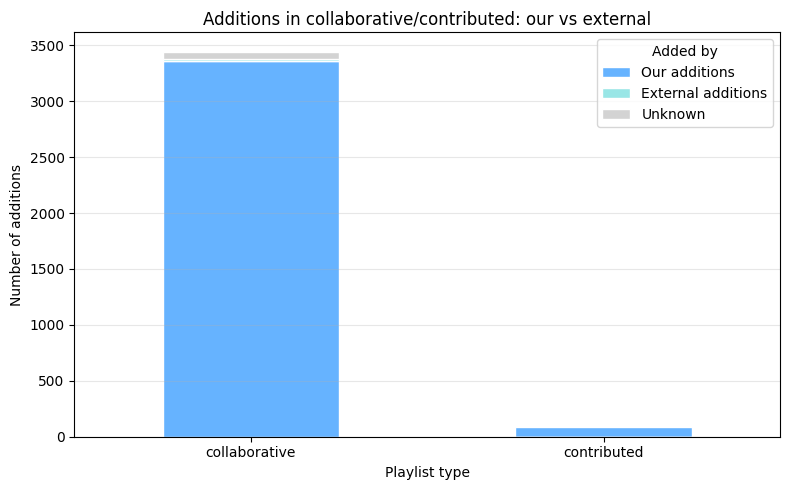


📊 Participants of collaborative and contributed playlists:


,Participant,Roles,Total additions,Share (%),Playlists
№,,,,,
1,Account 1,"owner, collaborator, contributor",3227,91.4,"2024_part_2, 2025, 2026, 202603, ambienr_post-..."
2,Account 3,"collaborator, owner",173,4.9,"2025, 2026, 202603, dark_feminine_siren_energy..."
3,Unknown,unknown,68,1.9,2025
4,Account 2,"collaborator, contributor, owner",44,1.2,"2024_part_2, by_ukr_ru, 🌑🌒🌕🌔moon"
5,External_1,external,20,0.6,by_ukr_ru



📌 Roles:
• owner        — playlist owner;
• collaborator — our other account in our own playlist;
• contributor  — our account in someone else's playlist;
• external     — external participant;
• unknown      — undefined (Exportify artifact, absent in API).


In [ ]:
# 4.1 Collaborator Explorer: обзорная ячейка

# Совместные (collaborative) и соавторские (contributed) плейлисты.
# Задача — понять, кто их наполняет: наши аккаунты, внешние участники
# или неопределённые (артефакт Exportify).
#
# Все ID и имена уже маскированы в блоке 0:
#   owner_id     → account_N
#   display_name → Account N
#   внешние Added By → user_NN

# Пересобираем owner_map на основе маскированных данных
owner_map = (
    playlists_metadata
    .drop_duplicates('name_norm')[['name_norm', 'owner_id']]
    .set_index('name_norm')['owner_id']
    .to_dict()
)

# Фильтруем collaborative и contributed
collab_contrib_links = playlist_links[
    playlist_links['playlist_type'].isin(['collaborative', 'contributed'])
].copy()

if collab_contrib_links.empty:
    print('No collaborative/contributed data.')
else:
    # ========== 1. Количество плейлистов по типам ==========
    type_counts = (
        collab_contrib_links
        .drop_duplicates('name_norm')['playlist_type']
        .value_counts()
        .reindex(['collaborative', 'contributed'])
        .fillna(0)
        .astype(int)
    )

    type_table = pd.DataFrame({
        'Type': type_counts.index,
        'Playlists': type_counts.values
    })
    type_table.index = range(1, len(type_table) + 1)
    type_table.index.name = '№'
    print('📊 Playlist count by type:')
    display(type_table)

    # ========== 2. Соотношение добавлений: наши / внешние / unknown ==========
    def group_by_actor(added_by):
        if pd.isna(added_by) or added_by == 'unknown':
            return 'unknown'
        return 'our' if added_by in owner_ids_set else 'external'

    collab_contrib_links['actor_group'] = collab_contrib_links['Added By'].apply(group_by_actor)

    group_counts = (
        collab_contrib_links
        .groupby(['playlist_type', 'actor_group'])
        .size()
        .unstack(fill_value=0)
    )

    for col in ['our', 'external', 'unknown']:
        if col not in group_counts.columns:
            group_counts[col] = 0

    group_counts = group_counts[['our', 'external', 'unknown']].reindex(
        ['collaborative', 'contributed'], fill_value=0
    )
    group_counts.columns = ['Our additions', 'External additions', 'Unknown']

    group_counts_with_total = group_counts.copy()
    group_counts_with_total.loc['Total'] = group_counts_with_total.sum()

    print('\n📊 Additions: our vs external vs unknown:')
    display(group_counts_with_total)

    # Stacked bar
    group_counts.plot(
        kind='bar', stacked=True, figsize=(8, 5),
        color=[COLORS['primary'], COLORS['secondary'], COLORS['muted']],
        edgecolor='white'
    )
    plt.title('Additions in collaborative/contributed: our vs external')
    plt.xlabel('Playlist type')
    plt.ylabel('Number of additions')
    plt.legend(title='Added by')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ========== 3. Таблица участников ==========
    # Наши — display_name (уже маскированный в Account N).
    # Внешние — External_N (счётчик по порядку появления).
    # Неопределённые — Unknown.
    added_by_to_name = {}
    external_counter = 1

    # Наши аккаунты — Account N, внешние — user_NN (уже маскированы),
    # неопределённые — Unknown.
    added_by_to_name = {}
    for added_by in collab_contrib_links['Added By'].unique():
        if pd.isna(added_by) or added_by == 'unknown':
            name = 'Unknown'
        elif added_by in owner_name_map:
            name = owner_name_map[added_by]
        else:
            # уже user_NN из маскированных данных
            name = added_by
        added_by_to_name[added_by] = name

    collab_contrib_links['actor_name'] = collab_contrib_links['Added By'].map(added_by_to_name)

    # Роль: owner / collaborator / contributor / external / unknown
    def get_role(row):
        added_by = row['Added By']
        name_norm = row['name_norm']
        owner = owner_map.get(name_norm)

        if pd.isna(added_by) or added_by == 'unknown':
            return 'unknown'
        if added_by in owner_ids_set:
            if owner is not None and added_by == owner:
                return 'owner'
            elif owner is not None:
                return 'collaborator'
            else:
                return 'contributor'
        else:
            return 'external'

    collab_contrib_links['role'] = collab_contrib_links.apply(get_role, axis=1)

    # Сводка по участникам
    rows = []
    for actor_name, group in collab_contrib_links.groupby('actor_name'):
        total_adds = len(group)
        share = total_adds / len(collab_contrib_links) * 100
        roles = ', '.join(dict.fromkeys(group['role']))
        playlists = sorted(group['name_norm'].unique())
        if len(playlists) > 6:
            playlist_str = ', '.join(playlists[:6]) + f' (+{len(playlists)-6})'
        else:
            playlist_str = ', '.join(playlists)

        rows.append({
            'Participant': actor_name,
            'Roles': roles,
            'Total additions': total_adds,
            'Share (%)': round(share, 1),
            'Playlists': playlist_str
        })

    actor_summary_df = pd.DataFrame(rows)
    actor_summary_df = actor_summary_df.sort_values('Total additions', ascending=False)
    actor_summary_df.index = range(1, len(actor_summary_df) + 1)
    actor_summary_df.index.name = '№'

    print('\n📊 Participants of collaborative and contributed playlists:')
    show_table(actor_summary_df)

    # ========== 4. Легенда ролей ==========
    print('\n📌 Roles:')
    print('• owner        — playlist owner;')
    print('• collaborator — our other account in our own playlist;')
    print('• contributor  — our account in someone else\'s playlist;')
    print('• external     — external participant;')
    print('• unknown      — undefined (Exportify artifact, absent in API).')